# EDA - RIDIRP

**Fuente:** Figshare, coleccion `6626162` - "Retinal Image Dataset of Infants and Retinopathy of Prematurity 2". DOI de coleccion `10.6084/m9.figshare.c.6626162.v1`. Paper asociado (DOI reportado por la propia API de Figshare como `resource_doi`): `10.1038/s41597-024-03409-7` (Scientific Data, 2024) - no verificado de forma independiente, ver `system/datasets_download/README.md`.

**Origen clinico:** cribado de ROP en el University Hospital Ostrava, Republica Checa.

**Contenido:** 188 recien nacidos, 6.004 imagenes retinianas organizadas en series longitudinales (multiples visitas por paciente), con metadatos clinicos por visita: sexo, edad gestacional (GA), peso al nacer (BW), edad postmenstrual (PMA) en esa visita puntual, codigo de diagnostico, forma de enfermedad Plus, y dispositivo de captura.

Este notebook explora el dataset **crudo**, tal como viene, antes de cualquier decision de mapeo/consenso (esas decisiones estan en `system/dataset_build/README.md`).

In [1]:
import re
import zipfile
import hashlib
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve().parent.parent  # system/eda/ -> ROP_paper/
RAW_DIR = ROOT / "datasets" / "RIDIRP_Original"
EXTRACTED_DIR = ROOT / "datasets" / "extracted" / "RIDIRP" / "images_stack_without_captions"

plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", 20)

In [11]:
db = pd.read_excel(RAW_DIR / "infant_retinal_database_info.xlsx", sheet_name="database")
print(db.head())
print("filas (visitas):", len(db), " | pacientes unicos:", db["ID"].nunique())

   ID SEX  GESTATIONAL AGE (GA)  BIRTH WEIGHT (BW)  POSTCONCEPTUAL AGE (PA)  \
0   1   F                    41               2905                44.000000   
1   1   F                    41               2905                47.000000   
2   1   F                    41               2905                50.000000   
3   2   M                    40               4040                41.000000   
4   2   M                    40               4040                43.285714   

   DIAGNOSIS CODE (DG)  PLUS FORM (PF)  DEVICE (D)  SERIE NUMBER (S)  
0                   11               0           1                 1  
1                   11               0           1                 2  
2                   11               0           1                 3  
3                   11               0           1                 1  
4                   11               0           1                 2  
filas (visitas): 484  | pacientes unicos: 188


In [ ]:
# Hoja principal: una fila = una visita (serie) de un paciente
db.columns = ["id", "sex", "ga", "bw", "pma", "dg", "pf", "device", "series"] # series es como el numero de visitas que tiene un paciente, cada visita tiene varias imagenes
print("filas (visitas):", len(db), " | pacientes unicos:", db["id"].nunique())
db.head(20)

filas (visitas): 484  | pacientes unicos: 188


,id,sex,ga,bw,pma,dg,pf,device,series
0,1,F,41,2905,44.000000,11,0,1,1
1,1,F,41,2905,47.000000,11,0,1,2
2,1,F,41,2905,50.000000,11,0,1,3
3,2,M,40,4040,41.000000,11,0,1,1
4,2,M,40,4040,43.285714,11,0,1,2
5,2,M,40,4040,45.285714,11,0,1,3
6,3,F,41,3950,42.285714,11,0,1,1
7,3,F,41,3950,55.571429,11,0,1,2
8,4,F,41,3760,42.142857,11,0,1,1
9,4,F,41,3760,45.428571,11,0,1,2


In [9]:
# Hojas de diccionario: que significa cada codigo
diagnosis = pd.read_excel(RAW_DIR / "infant_retinal_database_info.xlsx", sheet_name="diagnosis")
plus_form = pd.read_excel(RAW_DIR / "infant_retinal_database_info.xlsx", sheet_name="plus_form")
devices = pd.read_excel(RAW_DIR / "infant_retinal_database_info.xlsx", sheet_name="devices")

display(diagnosis)
display(plus_form)
display(devices)

,DIAGNOSIS,DIAGNOSIS_ID,DESCRIPTION
0,physiological,0,physiological
1,ROP 0,1,retinopathy of prematurity stage 0
2,ROP 1,2,retinopathy of prematurity stage 1
3,ROP 2,3,retinopathy of prematurity stage 2
4,ROP 3,4,retinopathy of prematurity stage 3
5,ROP 4A,5,retinopathy of prematurity stage 4a
6,ROP 4B,6,retinopathy of prematurity stage 4b
7,ROP 5,7,retinopathy of prematurity stage 5
8,AP - ROP,8,aggressive posterior retinopathy of prematurity
9,st.p. ROP,9,status post retinopathy of prematurity


,PLUS FORM,PLUS FORM ID
0,normal,0
1,pre-plus,1
2,plus,2


,DEVICE,DEVICE ID
0,Clarity RetCam 3,1
1,Phoenix ICON,2
2,Natus RetCam Envision,3


## Profundidad longitudinal: visitas por paciente

RIDIRP es la unica de las 4 fuentes con densidad temporal real (multiples visitas del mismo paciente con PMA creciente). Verificamos cuanta profundidad hay realmente.

count    188.000000
mean       2.574468
std        2.007949
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max       16.000000
dtype: float64


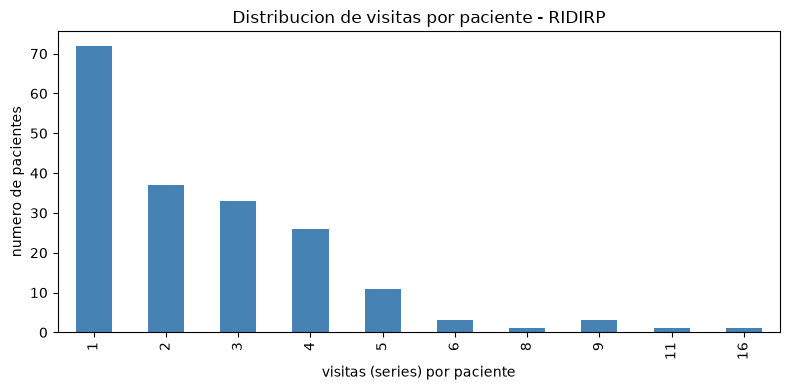

In [4]:
visits_per_patient = db.groupby("id").size()
print(visits_per_patient.describe())

fig, ax = plt.subplots()
visits_per_patient.value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue")
ax.set_xlabel("visitas (series) por paciente")
ax.set_ylabel("numero de pacientes")
ax.set_title("Distribucion de visitas por paciente - RIDIRP")
plt.tight_layout()
plt.show()

In [5]:
# Caso extremo real: paciente 43 (GA 24, BW 550g - muy prematuro), diagnostico AP-ROP (dg=8)
# 16 visitas reales siguiendo la progresion de la enfermedad semana a semana.
p43 = db[db["id"] == 43].sort_values("pma")
p43

,id,sex,ga,bw,pma,dg,pf,device,series
111,43,F,24,550,32.428571,8,2,1,1
112,43,F,24,550,32.857143,8,2,1,2
113,43,F,24,550,33.428571,8,2,1,3
114,43,F,24,550,34.857143,8,2,1,4
115,43,F,24,550,35.714286,8,2,1,5
116,43,F,24,550,36.428571,8,2,1,6
117,43,F,24,550,38.714286,8,2,1,7
118,43,F,24,550,38.857143,8,2,1,8
119,43,F,24,550,39.714286,8,2,1,9
120,43,F,24,550,40.714286,8,2,1,10


## Variables clinicas: GA, BW, PMA

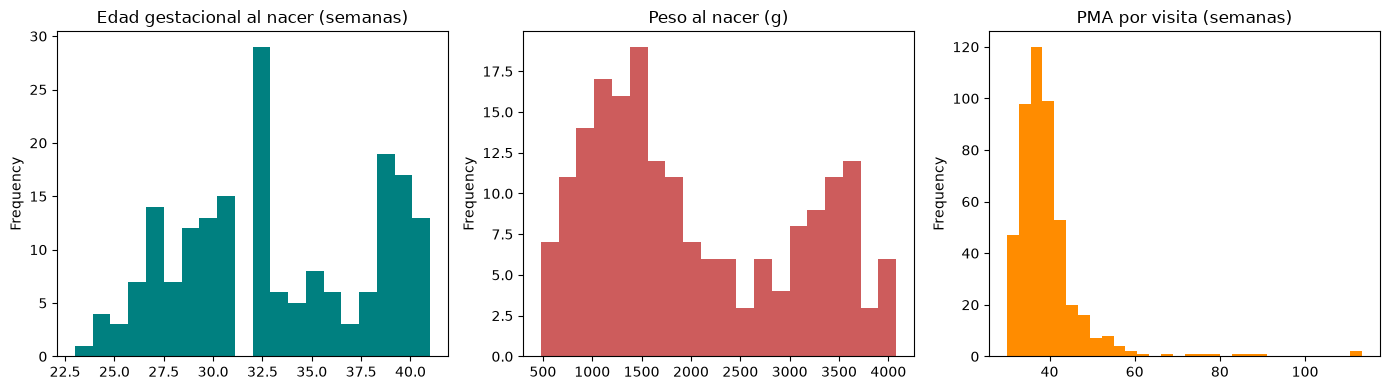

GA (pacientes): {'min': 23.0, 'mean': 33.180851063829785, 'max': 41.0}
BW (pacientes): {'min': 480.0, 'mean': 2016.5691489361702, 'max': 4080.0}
PMA (visitas): {'min': 30.0, 'mean': 39.476977567886664, 'max': 113.42857142857143}


In [6]:
# GA y BW son por paciente (constantes entre sus visitas); PMA varia por visita
patient_level = db.drop_duplicates("id")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
patient_level["ga"].plot(kind="hist", bins=20, ax=axes[0], color="teal")
axes[0].set_title("Edad gestacional al nacer (semanas)")
patient_level["bw"].plot(kind="hist", bins=20, ax=axes[1], color="indianred")
axes[1].set_title("Peso al nacer (g)")
db["pma"].plot(kind="hist", bins=30, ax=axes[2], color="darkorange")
axes[2].set_title("PMA por visita (semanas)")
plt.tight_layout()
plt.show()

print("GA (pacientes):", patient_level["ga"].describe()[["min", "mean", "max"]].to_dict())
print("BW (pacientes):", patient_level["bw"].describe()[["min", "mean", "max"]].to_dict())
print("PMA (visitas):", db["pma"].describe()[["min", "mean", "max"]].to_dict())

## Distribucion de diagnostico y Plus

El codigo de diagnostico (DG) mezcla estadios reales de ROP con hallazgos oculares que **no son ROP** (hemorragia, hamartoma, hipoplasia del nervio optico, toxoplasmosis) - hay que filtrarlos antes de usar esto como "estadio".

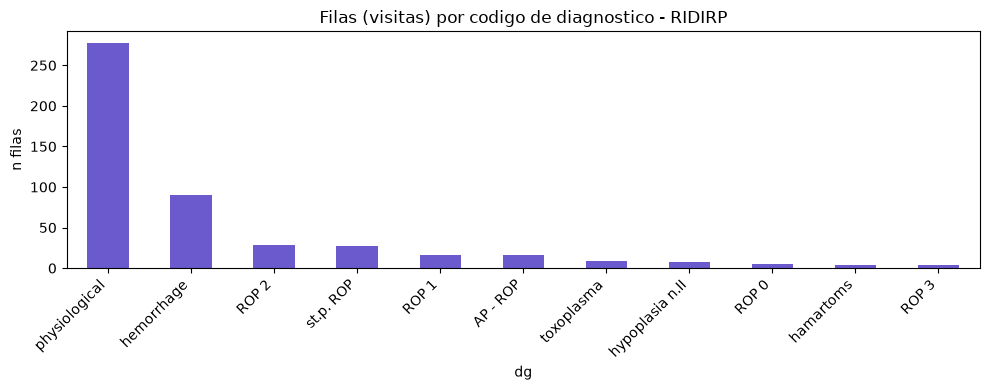

dg
physiological      278
hemorrhage          90
ROP 2               28
st.p. ROP           27
ROP 1               16
AP - ROP            16
toxoplasma           9
hypoplasia n.II      7
ROP 0                5
hamartoms            4
ROP 3                4
Name: count, dtype: int64

In [7]:
dg_names = dict(zip(diagnosis["DIAGNOSIS_ID"], diagnosis["DIAGNOSIS"]))
dg_counts = db["dg"].map(dg_names).value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
dg_counts.plot(kind="bar", ax=ax, color="slateblue")
ax.set_title("Filas (visitas) por codigo de diagnostico - RIDIRP")
ax.set_ylabel("n filas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
dg_counts

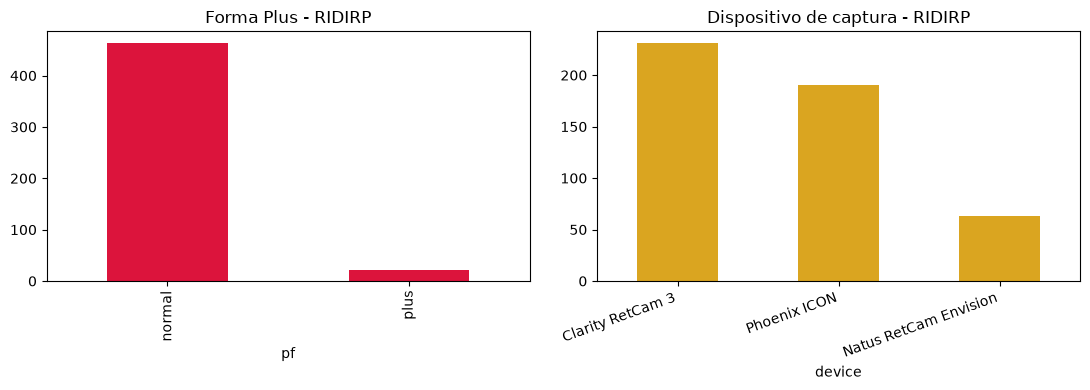

Plus: {'normal': 463, 'plus': 21}
ATENCION: no hay ningun caso 'pre-plus' en todo el dataset (0 filas).


In [8]:
pf_names = dict(zip(plus_form["PLUS FORM ID"], plus_form["PLUS FORM"]))
pf_counts = db["pf"].map(pf_names).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pf_counts.plot(kind="bar", ax=axes[0], color="crimson")
axes[0].set_title("Forma Plus - RIDIRP")

dev_names = dict(zip(devices["DEVICE ID"], devices["DEVICE"]))
db["device"].map(dev_names).value_counts().plot(kind="bar", ax=axes[1], color="goldenrod")
axes[1].set_title("Dispositivo de captura - RIDIRP")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print("Plus:", pf_counts.to_dict())
print("ATENCION: no hay ningun caso 'pre-plus' en todo el dataset (0 filas).")

## Problema de datos encontrado: columna `series` mal asignada (dispositivo 3)

La columna `SERIE NUMBER (S)` del xlsx **no es confiable como llave de union** con los archivos de imagen para ~31 filas, todas del dispositivo 3 (Natus RetCam Envision): varias visitas con PMA distinto comparten el mismo numero de serie en vez de incrementar. Ejemplo real, paciente 146.